# RecruitGen — Model 4 of 4: GAN (Synthetic Candidate Profiles for Dataset Augmentation)

**Goal:** generate realistic synthetic candidate profiles — the 9 RecruitGen features plus a job role — to augment
training data and to test the pipeline, and measure honestly whether that augmentation helps.

```
noise z + job role ─► Generator ─► 9 features ─► Critic (WGAN-GP) ◄─ real Kaggle profiles + job role
```

* **Model:** conditional WGAN-GP (Wasserstein loss + gradient penalty), PyTorch
* **Profile:** experience · projects · programming · analytics · ML/AI · cloud · communication · certifications · education · job role
* **Evaluation:** GAN quality & diversity (separately) · downstream job-role classifier: real only vs GAN-augmented on the
  **same untouched real test split** (accuracy, precision, recall, F1, classification report, confusion matrix) ·
  comparison with a CVAE baseline and random oversampling

**Outputs:** `generator.safetensors`, `discriminator.safetensors`, `config.json`, `metrics.json` (shown in the app's
*GAN Candidate Generator* page). All code lives in `models/gan/*.py`; this notebook runs it step by step.

## 1. Dataset — Kaggle Resume Dataset

**Link:** https://www.kaggle.com/datasets/snehaanbhawal/resume-dataset

| File | Content |
|---|---|
| `Resume/Resume.csv` | `ID`, `Resume_str` (plain text), `Resume_html`, `Category` — 2,484 resumes, 24 categories |
| `data/data/<CATEGORY>/<ID>.pdf` | the same resumes as PDF files (not needed for the GAN) |

**Setup — pick one:**

1. **Automatic** (default): the next cells call `kagglehub.dataset_download("snehaanbhawal/resume-dataset")`.
   The dataset is public; if Kaggle asks for authentication, put your API token in `~/.kaggle/kaggle.json`
   (Kaggle → Settings → API → *Create New Token*).
2. **Manual:** download the ZIP from the link above and extract it to `RecruitGen/data/kaggle_resume/`
   so that `RecruitGen/data/kaggle_resume/Resume/Resume.csv` exists.
3. **Kaggle CLI:** `kaggle datasets download -d snehaanbhawal/resume-dataset -p data/kaggle_resume --unzip`

You can also point `DATA_PATH` below (or the `RECRUITGEN_KAGGLE_DIR` environment variable) at any folder containing `Resume.csv`.

> **Important:** the dataset contains raw resume text and a category only — **not** the 9 RecruitGen features.
> They are extracted below with the app's own `feature_extractor.py`. The 24 Kaggle categories (HR, Chef,
> Information Technology, …) are used as the job-role condition; they are *not* the 5 roles of Transformer V3 / CVAE.

## 2. Setup

In [4]:

import os

print("CURRENT WORKING DIRECTORY:")
print(os.getcwd())

print("\nFILES AND FOLDERS HERE:")
print(os.listdir(os.getcwd()))

print("\nCHECKING PARENT FOLDERS:")
path = os.getcwd()

for i in range(5):
    print(f"\nLevel {i}: {path}")
    print(os.listdir(path)[:30])
    path = os.path.dirname(path)


CURRENT WORKING DIRECTORY:
/content

FILES AND FOLDERS HERE:
['.config', 'sample_data']

CHECKING PARENT FOLDERS:

Level 0: /content
['.config', 'sample_data']

Level 1: /
['sbin', 'tmp', 'lib', 'mnt', 'boot', 'srv', 'bin', 'dev', 'media', 'root', 'sys', 'usr', 'lib64', 'opt', 'run', 'proc', 'home', 'etc', 'var', 'kaggle', '.dockerenv', 'backend-container', 'datalab', 'tools', 'content', 'python-apt', 'python-apt.tar.xz', 'bin.usr-is-merged', 'sbin.usr-is-merged', 'lib.usr-is-merged']

Level 2: /
['sbin', 'tmp', 'lib', 'mnt', 'boot', 'srv', 'bin', 'dev', 'media', 'root', 'sys', 'usr', 'lib64', 'opt', 'run', 'proc', 'home', 'etc', 'var', 'kaggle', '.dockerenv', 'backend-container', 'datalab', 'tools', 'content', 'python-apt', 'python-apt.tar.xz', 'bin.usr-is-merged', 'sbin.usr-is-merged', 'lib.usr-is-merged']

Level 3: /
['sbin', 'tmp', 'lib', 'mnt', 'boot', 'srv', 'bin', 'dev', 'media', 'root', 'sys', 'usr', 'lib64', 'opt', 'run', 'proc', 'home', 'etc', 'var', 'kaggle', '.dockerenv', '

In [5]:

from google.colab import files

uploaded = files.upload()


Saving gan.zip to gan.zip


In [6]:
import os
import zipfile

ZIP_PATH = "/content/gan.zip"

print("ZIP exists:", os.path.exists(ZIP_PATH))

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    files = z.namelist()

    print("\nFiles inside gan.zip:")
    for file in files:
        print(file)

ZIP exists: True

Files inside gan.zip:
gan/
gan/baselines.py
gan/config.json
gan/dataset.py
gan/discriminator.safetensors
gan/evaluation.py
gan/gan.py
gan/GAN_Hybrid_Training.ipynb
gan/GAN_Training-1.ipynb
gan/GAN_Training.ipynb
gan/generator.safetensors
gan/hybrid.py
gan/hybrid_train.py
gan/llm_assist.py
gan/metrics.json
gan/outputs/
gan/outputs/config.json
gan/outputs/discriminator.safetensors
gan/outputs/generator.safetensors
gan/outputs/metrics.json
gan/train.py
gan/training.py
gan/__init__.py
gan/__pycache__/
gan/__pycache__/baselines.cpython-311.pyc
gan/__pycache__/dataset.cpython-311.pyc
gan/__pycache__/evaluation.cpython-311.pyc
gan/__pycache__/gan.cpython-310.pyc
gan/__pycache__/gan.cpython-311.pyc
gan/__pycache__/hybrid.cpython-311.pyc
gan/__pycache__/hybrid_train.cpython-311.pyc
gan/__pycache__/llm_assist.cpython-311.pyc
gan/__pycache__/train.cpython-311.pyc
gan/__pycache__/training.cpython-311.pyc
gan/__pycache__/__init__.cpython-310.pyc
gan/__pycache__/__init__.cpython-31

In [7]:
import os
import zipfile

ZIP_PATH = "/content/gan.zip"
GAN_DIR = "/content/models/gan"

os.makedirs(GAN_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    for file in z.namelist():
        if file.startswith("gan/") and not file.endswith("/"):
            relative_path = file[len("gan/"):]
            destination = os.path.join(GAN_DIR, relative_path)

            os.makedirs(os.path.dirname(destination), exist_ok=True)

            with z.open(file) as source, open(destination, "wb") as target:
                target.write(source.read())

print("GAN files extracted successfully!")
print("\nExtracted files:")
for file in sorted(os.listdir(GAN_DIR)):
    print(file)

GAN files extracted successfully!

Extracted files:
GAN_Hybrid_Training.ipynb
GAN_Training-1.ipynb
GAN_Training.ipynb
__init__.py
__pycache__
baselines.py
config.json
dataset.py
discriminator.safetensors
evaluation.py
gan.py
generator.safetensors
hybrid.py
hybrid_train.py
llm_assist.py
metrics.json
outputs
train.py
training.py


In [9]:
import os

print("Checking models folder:")

for root, dirs, files in os.walk("/content/models"):
    level = root.replace("/content/models", "").count(os.sep)
    indent = " " * 4 * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

Checking models folder:
models/
    gan/
        training.py
        config.json
        train.py
        hybrid_train.py
        evaluation.py
        gan.py
        baselines.py
        __init__.py
        GAN_Hybrid_Training.ipynb
        GAN_Training.ipynb
        dataset.py
        metrics.json
        GAN_Training-1.ipynb
        generator.safetensors
        discriminator.safetensors
        hybrid.py
        llm_assist.py
        __pycache__/
            llm_assist.cpython-311.pyc
            hybrid.cpython-311.pyc
            __init__.cpython-311.pyc
            gan.cpython-310.pyc
            gan.cpython-311.pyc
            hybrid_train.cpython-311.pyc
            evaluation.cpython-311.pyc
            train.cpython-311.pyc
            training.cpython-311.pyc
            dataset.cpython-313.pyc
            dataset.cpython-311.pyc
            baselines.cpython-311.pyc
            __init__.cpython-310.pyc
            __init__.cpython-313.pyc
        outputs/
            config

In [10]:
import inspect

files_to_check = [
    "/content/models/gan/dataset.py",
    "/content/models/gan/train.py",
    "/content/models/gan/training.py",
]

for path in files_to_check:
    print("\n" + "=" * 60)
    print("FILE:", path)
    print("=" * 60)

    with open(path, "r", encoding="utf-8") as f:
        lines = f.readlines()

    for i, line in enumerate(lines):
        if "transformer_v3" in line or "extract_features" in line or "FEATURE_ORDER" in line:
            print(f"Line {i+1}: {line.rstrip()}")


FILE: /content/models/gan/dataset.py
Line 11: (models/transformer_v3/feature_extractor.py), so generated profiles live in the app's feature space.
Line 27: from models.transformer_v3.feature_extractor import FEATURE_ORDER, extract_features
Line 36: FEATURE_NAMES = list(FEATURE_ORDER)
Line 98:     features = pd.DataFrame([extract_features(t) for t in text[keep]])[FEATURE_NAMES].astype(float)

FILE: /content/models/gan/train.py

FILE: /content/models/gan/training.py


In [11]:
from google.colab import files

uploaded = files.upload()

Saving feature_extractor.py to feature_extractor.py


In [12]:
import os
import shutil

os.makedirs("/content/models/transformer_v3", exist_ok=True)

shutil.move(
    "/content/feature_extractor.py",
    "/content/models/transformer_v3/feature_extractor.py"
)

print("Feature extractor added successfully!")

Feature extractor added successfully!


In [13]:
import sys
sys.path.insert(0, "/content")

from models.gan import dataset as ds
from models.gan.gan import Generator, Critic, CandidateGAN, save_checkpoint, MODEL_DIR
from models.gan.training import train_gan
from models.gan.train import verify_checkpoint, evaluate, build_metrics, write_metrics
from models.gan.evaluation import unit

print("SUCCESS: All GAN modules imported successfully!")

SUCCESS: All GAN modules imported successfully!


In [14]:
import inspect
import json

from models.gan.training import train_gan
from models.gan import train as gan_train

print("=" * 65)
print("1. ORIGINAL TRAINING FUNCTION")
print("=" * 65)

print(inspect.signature(train_gan))
print(inspect.getsource(train_gan))

print("\n" + "=" * 65)
print("2. ORIGINAL TRAIN SCRIPT CONFIGURATION")
print("=" * 65)

print(inspect.getsource(gan_train.run))

1. ORIGINAL TRAINING FUNCTION
(train_df, val_df, role_names, iterations=6000, batch_size=64, n_critic=5, gp_weight=10.0, lr=0.0002, seed=42, eval_every=100, log_every=250, dataset_report=None, log=<built-in function print>)
def train_gan(train_df, val_df, role_names, iterations=6000, batch_size=64, n_critic=5, gp_weight=10.0,
              lr=2e-4, seed=42, eval_every=100, log_every=250, dataset_report=None, log=print):
    """Train the conditional WGAN-GP. Returns (CandidateGAN with the best generator, critic, history, config)."""
    torch.manual_seed(seed)
    np.random.seed(seed)
    start = time.time()

    role_index = {r: i for i, r in enumerate(role_names)}
    X = torch.tensor(scale_features(train_df[FEATURE_NAMES].values, FEATURE_NAMES, FEATURE_BOUNDS))
    R = _one_hot(train_df["job_role"].map(role_index).values, len(role_names))
    n = len(X)

    G = Generator(len(FEATURE_NAMES), len(role_names), NOISE_DIM, HIDDEN_DIM)
    D = Critic(len(FEATURE_NAMES), len(role_names), H

In [15]:
import inspect
from models.gan import train as gan_train
from models.gan import dataset as ds
from models.gan import evaluation as ev

print("=" * 60)
print("1. DATA PREPARATION")
print("=" * 60)
print(inspect.signature(gan_train.prepare_data))
print(inspect.getsource(gan_train.prepare_data))

print("\n" + "=" * 60)
print("2. DATASET FUNCTIONS")
print("=" * 60)
print([name for name in dir(ds) if not name.startswith("_")])

print("\n" + "=" * 60)
print("3. EVALUATION FUNCTIONS")
print("=" * 60)
print([name for name in dir(ev) if not name.startswith("_")])

1. DATA PREPARATION
(data=None, download=True, seed=42, log=<built-in function print>)
def prepare_data(data=None, download=True, seed=42, log=print):
    csv_path = ds.find_resume_csv(data)
    if csv_path is None and download:
        log(f"Downloading {ds.KAGGLE_URL} with kagglehub ...")
        csv_path = ds.download_dataset()
    if csv_path is None:
        raise FileNotFoundError(
            f"Resume.csv not found. Download {ds.KAGGLE_URL} and extract it to data/kaggle_resume/ "
            "(or pass --data path/to/Resume.csv).")
    log(f"Dataset: {csv_path}")
    table, report = ds.build_feature_table(ds.load_raw(csv_path))
    table = ds.split_table(table, seed=seed)
    report["source_file"] = os.path.basename(csv_path)
    report["split_sizes"] = {k: int(v) for k, v in table["split"].value_counts().items()}
    ds.save_processed(table)
    log(f"Processed {report['rows']} resumes ({report['dropped_too_short']} too short, "
        f"{report['dropped_duplicate_text']} dupli

In [16]:
import inspect
from models.gan import dataset as ds
from models.gan import evaluation as ev

print("=" * 60)
print("1. DATASET FILE")
print("=" * 60)

csv_path = ds.find_resume_csv(None)
print("Resume.csv found:", csv_path)

print("\nProcessed dataset exists:", __import__("os").path.exists(ds.PROCESSED_PATH))
print("Processed dataset path:", ds.PROCESSED_PATH)

print("\n" + "=" * 60)
print("2. EVALUATION FUNCTION SIGNATURES")
print("=" * 60)

functions = [
    ev.c2st_auc,
    ev.quality_metrics,
    ev.generator_report,
    ev.diversity_metrics,
    ev.detailed_comparison,
    ev.augmentation_experiment,
    ev.tstr,
]

for func in functions:
    print(f"\n{func.__name__}{inspect.signature(func)}")

1. DATASET FILE
Resume.csv found: None

Processed dataset exists: False
Processed dataset path: /content/data/gan/kaggle_features.csv

2. EVALUATION FUNCTION SIGNATURES

c2st_auc(real_u, real_roles, syn_u, syn_roles, role_names, seed=0, folds=5)

quality_metrics(real_df, syn_values, syn_roles, role_names, seed=0)

generator_report(model, train_df, test_df, role_names, seed=0, multiplier=1)

diversity_metrics(syn_values, train_df, seed=0, max_pairs_rows=1500)

detailed_comparison(train_df, test_df, sampler, strategy_key, role_names, seed=0)

augmentation_experiment(train_df, val_df, test_df, samplers, role_names, seeds=(0, 1, 2, 3, 4), log=<built-in function print>)

tstr(train_df, test_df, sampler, role_names, seeds=(0, 1, 2, 3, 4))


In [17]:
import inspect
from models.gan import dataset as ds

print(inspect.getsource(ds.download_dataset))

def download_dataset():
    """Download with kagglehub (public dataset; uses ~/.kaggle/kaggle.json if present). Returns the Resume.csv path."""
    import kagglehub

    return find_resume_csv(kagglehub.dataset_download(KAGGLE_DATASET))



In [18]:
!pip install -q kagglehub

In [19]:
from models.gan import dataset as ds

print("Downloading original Kaggle Resume dataset...")

DATA_PATH = ds.download_dataset()

print("\nDataset downloaded successfully!")
print("Dataset path:", DATA_PATH)

Using Colab cache for faster access to the 'resume-dataset' dataset.

Dataset downloaded successfully!
Dataset path: /kaggle/input/resume-dataset/Resume/Resume.csv


In [20]:
from models.gan.train import prepare_data

print("Preparing GAN dataset...")

table, report = prepare_data(
    data=DATA_PATH,
    download=False,
    seed=42
)

train_df = table[table["split"] == "train"].reset_index(drop=True)
val_df = table[table["split"] == "val"].reset_index(drop=True)
test_df = table[table["split"] == "test"].reset_index(drop=True)

role_names = sorted(table["job_role"].unique())

print("\n" + "=" * 50)
print("DATASET SUMMARY")
print("=" * 50)

print("Total rows:", len(table))
print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Testing rows:", len(test_df))
print("Number of roles:", len(role_names))
print("Number of features:", len(ds.FEATURE_NAMES))

print("\nFeatures:", ds.FEATURE_NAMES)
print("\nRole names:", role_names)

Preparing GAN dataset...
Dataset: /kaggle/input/resume-dataset/Resume/Resume.csv
Processed 2481 resumes (1 too short, 2 duplicates dropped) -> /content/data/gan/kaggle_features.csv

DATASET SUMMARY
Total rows: 2481
Training rows: 1736
Validation rows: 372
Testing rows: 373
Number of roles: 24
Number of features: 9

Features: ['experience_years', 'projects_count', 'programming_score', 'data_analytics_score', 'ml_ai_score', 'cloud_score', 'communication_score', 'certification_count', 'education_level']

Role names: ['Accountant', 'Advocate', 'Agriculture', 'Apparel', 'Arts', 'Automobile', 'Aviation', 'BPO', 'Banking', 'Business Development', 'Chef', 'Construction', 'Consultant', 'Designer', 'Digital Media', 'Engineering', 'Finance', 'Fitness', 'HR', 'Healthcare', 'Information Technology', 'Public Relations', 'Sales', 'Teacher']


In [21]:
import inspect
import models.gan.training as training_module

print("=" * 60)
print("TRAINING MODULE IMPORTS AND HELPERS")
print("=" * 60)

print(inspect.getsource(training_module)[:14000])

TRAINING MODULE IMPORTS AND HELPERS
"""
GAN training — conditional WGAN-GP on the 9 features
----------------------------------------------------
Critic loss    = D(fake) - D(real) + λ · gradient penalty
Generator loss = -D(fake)

Model selection uses the validation split only: every `eval_every` iterations the generator samples a batch
with the validation role mix, and the checkpoint with the lowest mean per-feature Wasserstein distance to the
validation data is kept. The test split is never touched here.
"""

import copy
import time
from datetime import datetime

import numpy as np
import torch

from models.gan.dataset import FEATURE_BOUNDS, FEATURE_NAMES, INTEGER_FEATURES, KAGGLE_URL
from models.gan.gan import HIDDEN_DIM, NOISE_DIM, CandidateGAN, Critic, Generator, scale_features


def _one_hot(indices, n):
    out = torch.zeros(len(indices), n)
    out[torch.arange(len(indices)), torch.as_tensor(indices)] = 1.0
    return out


def gradient_penalty(critic, real, fake, role):
    al

In [22]:

import os, sys, json, shutil, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Make the RecruitGen project importable
ROOT = "/content"
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

from models.gan import dataset as ds
from models.gan.gan import (
    Generator, Critic, CandidateGAN,
    save_checkpoint, MODEL_DIR
)
from models.gan.training import train_gan
from models.gan.train import (
    verify_checkpoint, evaluate,
    build_metrics, write_metrics
)
from models.gan.evaluation import unit

# Reproducibility
SEED = 42

# GAN Training Configuration
QUICK_RUN = False
EPOCHS = 70
BATCH_SIZE = 64
N_CRITIC = 5

# Evaluation Configuration
EVAL_SEEDS = (0, 1, 2, 3, 4)
CVAE_EPOCHS = 150

# Dataset and output paths
DATA_PATH = "/kaggle/input/resume-dataset/Resume/Resume.csv"
OUTPUT_DIR = "/content/outputs"

# Export trained model to RecruitGen application
EXPORT_TO_APP = True

os.makedirs(OUTPUT_DIR, exist_ok=True)

start = time.time()

print("Setup completed successfully!")
print("GAN Training Epochs:", EPOCHS)
print("Batch Size:", BATCH_SIZE)
print("Critic Updates:", N_CRITIC)
print("Evaluation Seeds:", EVAL_SEEDS)
print("Dataset:", DATA_PATH)


Setup completed successfully!
GAN Training Epochs: 70
Batch Size: 64
Critic Updates: 5
Evaluation Seeds: (0, 1, 2, 3, 4)
Dataset: /kaggle/input/resume-dataset/Resume/Resume.csv


## 3. Load and inspect the raw dataset

In [23]:
csv_path = ds.find_resume_csv(DATA_PATH) or ds.download_dataset()

raw = ds.load_raw(csv_path)

print("File:", csv_path)
print("Shape:", raw.shape, "| columns:", list(raw.columns))
print("Missing values:", raw.isna().sum().to_dict())
print("Duplicate resume texts:", int(raw["Resume_str"].duplicated().sum()))

raw["Category"].value_counts()

File: /kaggle/input/resume-dataset/Resume/Resume.csv
Shape: (2484, 4) | columns: ['ID', 'Resume_str', 'Resume_html', 'Category']
Missing values: {'ID': 0, 'Resume_str': 0, 'Resume_html': 0, 'Category': 0}
Duplicate resume texts: 2


,count
Category,
INFORMATION-TECHNOLOGY,120
BUSINESS-DEVELOPMENT,120
ADVOCATE,118
CHEF,118
ENGINEERING,118
ACCOUNTANT,118
FINANCE,118
FITNESS,117
AVIATION,117


In [24]:
print(raw.loc[0, "Resume_str"][:1200])
raw["Resume_str"].str.len().describe().round(0)

         HR ADMINISTRATOR/MARKETING ASSOCIATE

HR ADMINISTRATOR       Summary     Dedicated Customer Service Manager with 15+ years of experience in Hospitality and Customer Service Management.   Respected builder and leader of customer-focused teams; strives to instill a shared, enthusiastic commitment to customer service.         Highlights         Focused on customer satisfaction  Team management  Marketing savvy  Conflict resolution techniques     Training and development  Skilled multi-tasker  Client relations specialist           Accomplishments      Missouri DOT Supervisor Training Certification  Certified by IHG in Customer Loyalty and Marketing by Segment   Hilton Worldwide General Manager Training Certification  Accomplished Trainer for cross server hospitality systems such as    Hilton OnQ  ,   Micros    Opera PMS   , Fidelio    OPERA    Reservation System (ORS) ,   Holidex    Completed courses and seminars in customer service, sales strategies, inventory control, loss preve

,Resume_str
count,2484.0
mean,6295.0
std,2769.0
min,21.0
25%,5160.0
50%,5886.0
75%,7227.0
max,38842.0


## 4. Preprocessing — resume text → 9 features

1. drop resumes too short for the extractor and exact duplicate texts
2. extract the 9 features with `models/transformer_v3/feature_extractor.py` (the extractor the app uses)
3. clip to the app's input ranges — the extractor occasionally reads phrases such as "500 certificates" as a count
4. stratified **train / validation / test** split (70 / 15 / 15). The GAN and the CVAE baseline are trained on train,
   tuned on validation; **test is only used for the final report**.

In [25]:
table, report = ds.build_feature_table(raw)
table = ds.split_table(table, seed=SEED)

report["source_file"] = os.path.basename(csv_path)
report["split_sizes"] = {
    k: int(v) for k, v in table["split"].value_counts().items()
}

ds.save_processed(table)

print(json.dumps(
    {k: v for k, v in report.items() if k != "role_counts"},
    indent=2
))

table[ds.FEATURE_NAMES].describe().round(2).T

{
  "raw_rows": 2484,
  "raw_categories": 24,
  "dropped_too_short": 1,
  "dropped_duplicate_text": 2,
  "clipped_values": {
    "experience_years": 48,
    "projects_count": 50,
    "certification_count": 120
  },
  "rows": 2481,
  "source_file": "Resume.csv",
  "split_sizes": {
    "train": 1736,
    "test": 373,
    "val": 372
  }
}


,count,mean,std,min,25%,50%,75%,max
experience_years,2481.0,1.82,4.87,0.0,0.0,0.0,0.0,20.0
projects_count,2481.0,0.92,2.86,0.0,0.0,0.0,1.0,20.0
programming_score,2481.0,7.88,17.28,0.0,0.0,0.0,15.0,100.0
data_analytics_score,2481.0,18.40,15.71,0.0,15.0,15.0,30.0,100.0
ml_ai_score,2481.0,25.58,11.23,0.0,15.0,30.0,30.0,100.0
cloud_score,2481.0,13.15,10.21,0.0,0.0,15.0,15.0,100.0
communication_score,2481.0,55.30,13.26,40.0,50.0,50.0,60.0,100.0
certification_count,2481.0,0.90,3.39,0.0,0.0,0.0,0.0,15.0
education_level,2481.0,2.13,0.86,1.0,1.0,2.0,3.0,5.0


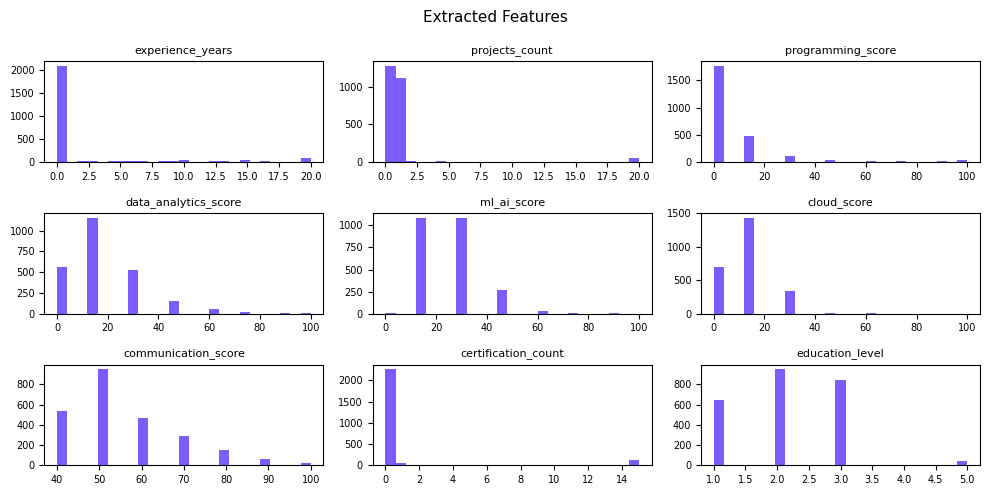

Train: 1736 | Val: 372 | Test: 373 | Roles: 24


,experience_years,projects_count,programming_score,data_analytics_score,ml_ai_score,cloud_score,communication_score,certification_count,education_level
job_role,,,,,,,,,
Accountant,1.9,0.7,1.8,25.9,23.8,14.5,51.0,0.4,2.3
Advocate,2.0,0.5,3.8,15.6,25.3,15.3,57.9,1.0,2.0
Agriculture,2.1,1.2,8.0,20.5,25.7,14.0,55.7,0.7,2.5
Apparel,1.0,0.6,3.4,15.7,24.6,12.2,54.9,1.2,1.8
Arts,1.6,0.4,5.1,13.1,23.3,11.5,56.2,1.0,2.3
Automobile,2.8,0.8,7.1,24.4,27.5,14.2,54.7,1.3,2.0
Aviation,1.9,0.9,7.0,15.4,23.7,13.6,51.6,1.4,2.0
BPO,2.3,0.6,8.6,28.6,26.6,9.5,53.6,1.5,2.1
Banking,1.5,0.6,6.3,21.1,27.4,11.7,55.4,0.8,2.1


In [27]:

fig, ax = plt.subplots(3, 3, figsize=(10, 5))

for a, f in zip(ax.flat, ds.FEATURE_NAMES):
    a.hist(table[f], bins=25, color="#7C5CFC")
    a.set_title(f, fontsize=8)
    a.tick_params(axis="both", labelsize=7)

plt.suptitle("Extracted Features", fontsize=11)
plt.tight_layout()
plt.show()

train, val, test = (
    table[table["split"] == s].reset_index(drop=True)
    for s in ("train", "val", "test")
)

role_names = sorted(table["job_role"].unique())

print("Train:", len(train), "| Val:", len(val),
      "| Test:", len(test), "| Roles:", len(role_names))

table.groupby("job_role")[ds.FEATURE_NAMES].mean().round(1)


## 5. Model — conditional WGAN-GP

* **Generator:** `[z (32) ‖ role one-hot]` → 128 → 256 → 128 → 9 (`tanh`, features scaled to [-1, 1] with fixed bounds)
* **Critic:** `[features ‖ role one-hot]` → 256 → 128 → 1 (no sigmoid, no batch norm)
* **Loss:** critic `D(fake) − D(real) + 10·GP`, generator `−D(fake)`; 5 critic steps per generator step, Adam (0.5, 0.9)
* **Post-processing:** generated values are mapped back to real units and snapped to the nearest value observed in
  the training data, because the extractor only produces discrete values (scores in steps of 15, counts, levels).

In [28]:
print(Generator(len(ds.FEATURE_NAMES), len(role_names)))
print(Critic(len(ds.FEATURE_NAMES), len(role_names)))

Generator(
  (net): Sequential(
    (0): Linear(in_features=56, out_features=128, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=128, out_features=256, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Linear(in_features=128, out_features=9, bias=True)
    (7): Tanh()
  )
)
Critic(
  (net): Sequential(
    (0): Linear(in_features=33, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
)


## 6. Training (checkpoint selected on the validation split)

In [31]:

import copy
import time
import numpy as np
import torch

from models.gan.training import (
    _one_hot,
    gradient_penalty,
    build_config,
    validation_distance
)

from models.gan.gan import (
    Generator,
    Critic,
    CandidateGAN,
    scale_features,
    NOISE_DIM,
    HIDDEN_DIM
)

# ==========================================
# 1. TRAINING CONFIGURATION
# ==========================================

EPOCHS = 70
BATCH_SIZE = 64
N_CRITIC = 5
GP_WEIGHT = 10.0
LEARNING_RATE = 0.0002
SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cpu")
start_time = time.time()

# ==========================================
# 2. PREPARE DATA
# ==========================================

role_index = {role: i for i, role in enumerate(role_names)}

X = torch.tensor(
    scale_features(
        train[ds.FEATURE_NAMES].values,
        ds.FEATURE_NAMES,
        ds.FEATURE_BOUNDS
    ),
    dtype=torch.float32,
    device=device
)

R = _one_hot(
    train["job_role"].map(role_index).values,
    len(role_names)
).float().to(device)

n = len(X)
steps_per_epoch = int(np.ceil(n / BATCH_SIZE))

print("Training samples:", n)
print("Steps per epoch:", steps_per_epoch)
print("Total epochs:", EPOCHS)
print("Device:", device)

# ==========================================
# 3. INITIALIZE FRESH MODELS
# ==========================================

G = Generator(
    len(ds.FEATURE_NAMES),
    len(role_names),
    NOISE_DIM,
    HIDDEN_DIM
).to(device)

D = Critic(
    len(ds.FEATURE_NAMES),
    len(role_names),
    HIDDEN_DIM
).to(device)

opt_g = torch.optim.Adam(
    G.parameters(),
    lr=LEARNING_RATE,
    betas=(0.5, 0.9)
)

opt_d = torch.optim.Adam(
    D.parameters(),
    lr=LEARNING_RATE,
    betas=(0.5, 0.9)
)

# ==========================================
# 4. CONFIGURATION AND CHECKPOINT
# ==========================================

total_generator_updates = EPOCHS * steps_per_epoch

hparams = {
    "epochs": EPOCHS,
    "iterations": total_generator_updates,
    "batch_size": BATCH_SIZE,
    "n_critic": N_CRITIC,
    "gp_weight": GP_WEIGHT,
    "learning_rate": LEARNING_RATE,
    "seed": SEED,
    "selection": "lowest validation Wasserstein distance",
    "training_method": "shuffled full-dataset passes"
}

config = build_config(train, role_names, hparams, report)

history = []

best = {
    "distance": float("inf"),
    "epoch": 0,
    "iteration": 0,
    "generator_state": None,
    "critic_state": None
}

global_iteration = 0

# ==========================================
# 5. TRAINING LOOP
# ==========================================

for epoch in range(1, EPOCHS + 1):

    G.train()
    D.train()

    permutation = torch.randperm(n, device=device)

    critic_losses = []
    generator_losses = []
    gp_values = []
    wasserstein_values = []

    for start_idx in range(0, n, BATCH_SIZE):

        indices = permutation[start_idx:start_idx + BATCH_SIZE]

        real = X[indices]
        role = R[indices]
        current_batch = len(real)

        # Train Critic
        for _ in range(N_CRITIC):

            noise = torch.randn(current_batch, NOISE_DIM, device=device)
            fake = G(noise, role).detach()

            d_real = D(real, role).mean()
            d_fake = D(fake, role).mean()

            gp = gradient_penalty(D, real, fake, role)

            # Original WGAN-GP loss
            loss_d = d_fake - d_real + GP_WEIGHT * gp

            opt_d.zero_grad()
            loss_d.backward()
            opt_d.step()

            critic_losses.append(loss_d.item())
            gp_values.append(gp.item())
            wasserstein_values.append((d_real - d_fake).item())

        # Train Generator
        noise = torch.randn(current_batch, NOISE_DIM, device=device)

        generated = G(noise, role)
        loss_g = -D(generated, role).mean()

        opt_g.zero_grad()
        loss_g.backward()
        opt_g.step()

        generator_losses.append(loss_g.item())
        global_iteration += 1

    # ======================================
    # 6. VALIDATION
    # ======================================

    G.eval()
    D.eval()

    current_model = CandidateGAN(
        generator=G,
        config=config
    )

    val_dist = validation_distance(
        current_model,
        val,
        seed=SEED
    )

    epoch_result = {
        "epoch": epoch,
        "iteration": global_iteration,
        "critic_loss": float(np.mean(critic_losses)),
        "critic_loss_magnitude": float(abs(np.mean(critic_losses))),
        "generator_loss": float(np.mean(generator_losses)),
        "wasserstein_estimate": float(np.mean(wasserstein_values)),
        "gradient_penalty": float(np.mean(gp_values)),
        "val_distance": float(val_dist)
    }

    history.append(epoch_result)

    # Save best Generator and Critic
    if val_dist < best["distance"]:

        best = {
            "distance": float(val_dist),
            "epoch": epoch,
            "iteration": global_iteration,
            "generator_state": copy.deepcopy(G.state_dict()),
            "critic_state": copy.deepcopy(D.state_dict())
        }

    # ======================================
    # 7. DISPLAY EVERY EPOCH
    # ======================================

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"G Loss: {epoch_result['generator_loss']:.4f} | "
        f"D Loss Magnitude: {epoch_result['critic_loss_magnitude']:.4f} | "
        f"GP: {epoch_result['gradient_penalty']:.4f} | "
        f"W Estimate: {epoch_result['wasserstein_estimate']:.4f} | "
        f"Val Distance: {val_dist:.5f}"
    )

# ==========================================
# 8. RESTORE BEST MODEL
# ==========================================

G.load_state_dict(best["generator_state"])
D.load_state_dict(best["critic_state"])

G.eval()
D.eval()

training_seconds = time.time() - start_time

config["training"].update({
    "epochs": EPOCHS,
    "best_epoch": best["epoch"],
    "best_iteration": best["iteration"],
    "best_val_distance": best["distance"],
    "seconds": training_seconds,
    "training_method": "shuffled full-dataset passes"
})

model = CandidateGAN(
    generator=G,
    config=config
)

critic = D

# ==========================================
# 9. FINAL TRAINING SUMMARY
# ==========================================

print("\n" + "=" * 55)
print("GAN RETRAINING COMPLETED")
print("=" * 55)

print("Epochs completed:", EPOCHS)
print("Generator updates:", global_iteration)
print("Critic updates:", global_iteration * N_CRITIC)
print("Best epoch:", best["epoch"])
print("Best validation distance:", round(best["distance"], 5))
print("Training time:", round(training_seconds / 60, 2), "minutes")
print("Generator parameters:", sum(p.numel() for p in G.parameters()))

# Store training history
history_df = pd.DataFrame(history)
history_df.to_csv(
    os.path.join(OUTPUT_DIR, "gan_70_epoch_history.csv"),
    index=False
)

print("Training history saved successfully.")


Training samples: 1736
Steps per epoch: 28
Total epochs: 70
Device: cpu
Epoch 01/70 | G Loss: -0.2343 | D Loss Magnitude: 1.2595 | GP: 0.1716 | W Estimate: 0.4568 | Val Distance: 0.31918
Epoch 02/70 | G Loss: -0.3948 | D Loss Magnitude: 1.5475 | GP: 0.0071 | W Estimate: 1.6189 | Val Distance: 0.16020
Epoch 03/70 | G Loss: -1.5919 | D Loss Magnitude: 0.4456 | GP: 0.0043 | W Estimate: 0.4891 | Val Distance: 0.07197
Epoch 04/70 | G Loss: -0.6237 | D Loss Magnitude: 0.3166 | GP: 0.0139 | W Estimate: 0.4556 | Val Distance: 0.10112
Epoch 05/70 | G Loss: 0.5809 | D Loss Magnitude: 0.4597 | GP: 0.0143 | W Estimate: 0.6023 | Val Distance: 0.08035
Epoch 06/70 | G Loss: 0.0296 | D Loss Magnitude: 0.4251 | GP: 0.0117 | W Estimate: 0.5425 | Val Distance: 0.08471
Epoch 07/70 | G Loss: 0.0102 | D Loss Magnitude: 0.4930 | GP: 0.0121 | W Estimate: 0.6142 | Val Distance: 0.07485
Epoch 08/70 | G Loss: 0.4726 | D Loss Magnitude: 0.5121 | GP: 0.0119 | W Estimate: 0.6314 | Val Distance: 0.07464
Epoch 09/70 

In [32]:

# Save the best trained GAN checkpoint
save_checkpoint(
    model.generator,
    critic,
    config,
    OUTPUT_DIR
)

print("GAN checkpoint saved successfully!")

# Verify the saved checkpoint
check = verify_checkpoint(model, OUTPUT_DIR)

print("\nCheckpoint verification:")
print(check)

# Save training configuration
with open(
    os.path.join(OUTPUT_DIR, "gan_70_epoch_config.json"),
    "w"
) as f:
    json.dump(config, f, indent=2)

print("\nConfiguration saved successfully!")


GAN checkpoint saved successfully!

Checkpoint verification:
{'reloaded': True, 'identical_samples': True, 'params': 74377}

Configuration saved successfully!


In [33]:

import inspect
import models.gan.evaluation as ev

print("C2ST:", inspect.signature(ev.c2st_auc))
print("Quality metrics:", inspect.signature(ev.quality_metrics))
print("Generator report:", inspect.signature(ev.generator_report))
print("Evaluation function:", inspect.signature(evaluate))


C2ST: (real_u, real_roles, syn_u, syn_roles, role_names, seed=0, folds=5)
Quality metrics: (real_df, syn_values, syn_roles, role_names, seed=0)
Generator report: (model, train_df, test_df, role_names, seed=0, multiplier=1)
Evaluation function: (model, train, val, test, role_names, seeds, cvae_epochs=150, log=<built-in function print>)


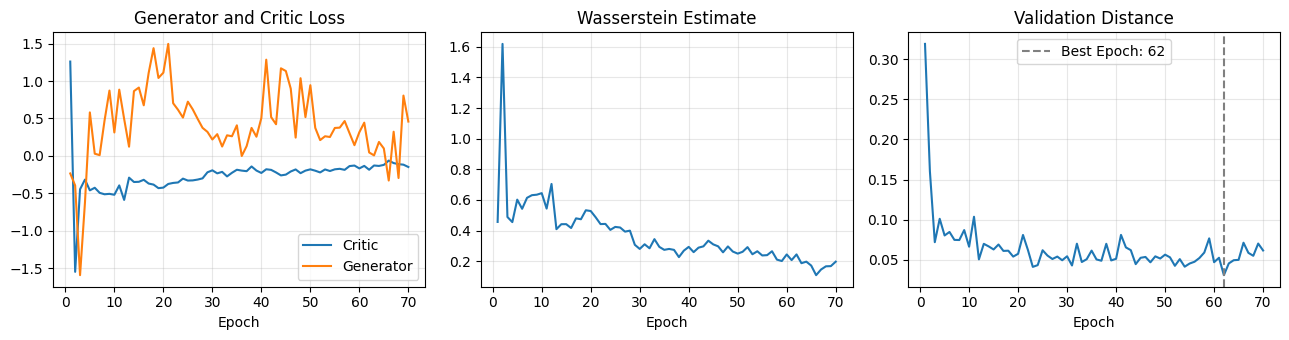

In [34]:

# 70-Epoch GAN Training Performance Graphs

h = pd.DataFrame(history)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))

# 1. Generator and Critic losses
ax[0].plot(h["epoch"], h["critic_loss"], label="Critic")
ax[0].plot(h["epoch"], h["generator_loss"], label="Generator")
ax[0].set_title("Generator and Critic Loss")
ax[0].legend()

# 2. Wasserstein estimate
ax[1].plot(h["epoch"], h["wasserstein_estimate"])
ax[1].set_title("Wasserstein Estimate")

# 3. Validation distance
ax[2].plot(h["epoch"], h["val_distance"])
ax[2].axvline(
    best["epoch"],
    linestyle="--",
    color="grey",
    label=f"Best Epoch: {best['epoch']}"
)
ax[2].set_title("Validation Distance")
ax[2].legend()

for a in ax:
    a.set_xlabel("Epoch")
    a.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 7. Generate synthetic profiles (clearly labelled as synthetic)

In [35]:

# Generate 10 synthetic candidate profiles
sample = pd.DataFrame(
    model.generate("Information Technology", 10, seed=SEED)
)

sample.insert(0, "data_source", "SYNTHETIC (GAN)")

display(sample)


,data_source,experience_years,projects_count,programming_score,data_analytics_score,ml_ai_score,cloud_score,communication_score,certification_count,education_level,job_role
0,SYNTHETIC (GAN),0.0,0,0.0,60.0,45.0,15.0,50.0,0,2,Information Technology
1,SYNTHETIC (GAN),0.0,3,45.0,45.0,45.0,15.0,50.0,0,3,Information Technology
2,SYNTHETIC (GAN),15.0,0,0.0,30.0,30.0,30.0,70.0,11,2,Information Technology
3,SYNTHETIC (GAN),0.2,3,45.0,45.0,45.0,30.0,50.0,0,3,Information Technology
4,SYNTHETIC (GAN),0.2,0,0.0,15.0,15.0,30.0,50.0,0,2,Information Technology
5,SYNTHETIC (GAN),0.0,1,0.0,30.0,30.0,15.0,50.0,0,2,Information Technology
6,SYNTHETIC (GAN),0.0,0,0.0,30.0,30.0,15.0,60.0,0,2,Information Technology
7,SYNTHETIC (GAN),0.0,1,0.0,30.0,45.0,15.0,40.0,0,2,Information Technology
8,SYNTHETIC (GAN),18.0,1,0.0,45.0,45.0,30.0,70.0,5,2,Information Technology
9,SYNTHETIC (GAN),0.0,0,0.0,15.0,15.0,15.0,40.0,0,1,Information Technology


## 8. Save the checkpoint and test reloading it

In [36]:
save_checkpoint(model.generator, critic, config, OUTPUT_DIR)
check = verify_checkpoint(model, OUTPUT_DIR)
print(check)
assert check["identical_samples"], "Reloaded generator does not reproduce the trained one"
print("Saved:", sorted(os.listdir(OUTPUT_DIR)))

{'reloaded': True, 'identical_samples': True, 'params': 74377}
Saved: ['config.json', 'discriminator.safetensors', 'gan_70_epoch_config.json', 'gan_70_epoch_history.csv', 'generator.safetensors']


## 9. Evaluation

* **Quality / diversity** of each generator against the held-out real test split, next to a *real reference*
  (real training rows scored the same way = what a perfect generator would reach).
* **Downstream job-role classifier** (Random Forest, 9 features): real only vs real + GAN vs real + CVAE baseline vs
  real + random oversampling. Four augmentation strategies; the one with the best **validation** macro-F1 is reported
  on the **test** split, averaged over several seeds.
* **TSTR:** train on synthetic only, test on real.
* **CVAE baseline:** same layer sizes as `models/cvae/` but retrained on this split (the shipped CVAE is conditioned
  on 5 different roles and is left unchanged).

In [ ]:
results = evaluate(model, train, val, test, role_names, EVAL_SEEDS, cvae_epochs=CVAE_EPOCHS)

Training the CVAE baseline (same layer sizes as models/cvae) on the same split ...


CVAE baseline: best val loss 0.2354 after 65 epochs
Quality & diversity against the held-out test split ...


Downstream job-role classifier: real only vs augmented (same untouched test split) ...


real only            | test macro-F1 0.0865


GAN                  | chosen balance    | test macro-F1 0.0807 (Δ -0.0058 ± 0.0078, improved on 2/5 seeds)


CVAE baseline        | chosen balance    | test macro-F1 0.0795 (Δ -0.0070 ± 0.0065, improved on 1/5 seeds)


Random oversampling  | chosen ratio_2.0  | test macro-F1 0.0813 (Δ -0.0052 ± 0.0139, improved on 2/5 seeds)


TSTR (train on synthetic only, test on real) ...


In [ ]:
quality = pd.DataFrame([{
    "generator": name,
    "mean KS": q["quality"]["mean_ks_statistic"], "mean Wasserstein (0-1)": q["quality"]["mean_wasserstein_0_1"],
    "correlation gap": q["quality"]["correlation_gap"], "per-role mean gap": q["quality"]["per_role_mean_gap_0_1"],
    "C2ST AUC": q["quality"]["c2st_auc"], "unique rows": q["diversity"]["unique_row_ratio"],
    "exact train copies": q["diversity"]["exact_train_copy_rate"], "DCR median": q["diversity"]["dcr_median"],
    "pairwise distance": q["diversity"]["mean_pairwise_distance"],
} for name, q in results["quality"].items()]).set_index("generator")
quality.round(4)

,mean KS,mean Wasserstein (0-1),correlation gap,per-role mean gap,C2ST AUC,unique rows,exact train copies,DCR median,pairwise distance
generator,,,,,,,,,
Real reference,0.0343,0.0180,0.0506,0.0510,0.4777,0.8257,0.4772,0.0500,0.5964
GAN,0.1415,0.0365,0.0941,0.0572,0.8624,0.8123,0.3673,0.1000,0.7125
CVAE baseline,0.4138,0.0795,0.1403,0.0450,0.9999,0.1448,0.0000,0.1202,0.1602


In [ ]:
aug = results["augmentation"]
rows = [{"training data": "real only", "strategy": "-", **{k: f"{v['mean']:.4f} ± {v['std']:.4f}" for k, v in aug["real_only"]["test"].items()}}]
for name, s in aug["samplers"].items():
    c = s["strategies"][s["chosen_strategy"]]
    rows.append({"training data": f"real + {name}", "strategy": c["label"],
                 **{k: f"{v['mean']:.4f} ± {v['std']:.4f}" for k, v in c["test"].items()},
                 "Δ macro-F1": f"{s['test_f1_macro_delta_vs_real']['mean']:+.4f}",
                 "seeds improved": f"{s['test_f1_macro_delta_vs_real']['seeds_improved']}/{s['test_f1_macro_delta_vs_real']['seeds']}"})
print("Test split (untouched, real resumes only):")
pd.DataFrame(rows).set_index("training data")

Test split (untouched, real resumes only):


,strategy,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,Δ macro-F1,seeds improved
training data,,,,,,,,
real only,-,0.0895 ± 0.0065,0.0911 ± 0.0076,0.0854 ± 0.0059,0.0865 ± 0.0064,0.0902 ± 0.0069,NaN,NaN
real + GAN,Balance every role to the largest,0.0815 ± 0.0021,0.0851 ± 0.0030,0.0819 ± 0.0083,0.0807 ± 0.0041,0.0828 ± 0.0011,-0.0058,2/5
real + CVAE baseline,Balance every role to the largest,0.0810 ± 0.0069,0.0859 ± 0.0076,0.0772 ± 0.0062,0.0795 ± 0.0068,0.0830 ± 0.0074,-0.0070,1/5
real + Random oversampling,+200% synthetic per role,0.0847 ± 0.0095,0.0860 ± 0.0072,0.0804 ± 0.0088,0.0813 ± 0.0077,0.0853 ± 0.0085,-0.0052,2/5


In [ ]:
pd.DataFrame([{"sampler": n, "strategy": st["label"], "synthetic rows": st["synthetic_rows"],
               "val macro-F1": round(st["val"]["f1_macro"]["mean"], 4), "test macro-F1": round(st["test"]["f1_macro"]["mean"], 4),
               "chosen": k == s["chosen_strategy"]}
              for n, s in aug["samplers"].items() for k, st in s["strategies"].items()])

,sampler,strategy,synthetic rows,val macro-F1,test macro-F1,chosen
0,GAN,+50% synthetic per role,866,0.0829,0.0867,False
1,GAN,+100% synthetic per role,1736,0.0898,0.0871,False
2,GAN,+200% synthetic per role,3472,0.0936,0.0837,False
3,GAN,Balance every role to the largest,280,0.1008,0.0807,True
4,CVAE baseline,+50% synthetic per role,866,0.0838,0.0836,False
5,CVAE baseline,+100% synthetic per role,1736,0.0831,0.0767,False
6,CVAE baseline,+200% synthetic per role,3472,0.0858,0.0765,False
7,CVAE baseline,Balance every role to the largest,280,0.0996,0.0795,True
8,Random oversampling,+50% synthetic per role,866,0.0956,0.0706,False
9,Random oversampling,+100% synthetic per role,1736,0.0921,0.0773,False


===== real_only (test split, seed 0) =====
                        precision    recall  f1-score   support

            Accountant     0.1111    0.1111    0.1111        18
              Advocate     0.0385    0.0556    0.0455        18
           Agriculture     0.2500    0.2222    0.2353         9
               Apparel     0.0667    0.0667    0.0667        15
                  Arts     0.0000    0.0000    0.0000        16
            Automobile     0.0000    0.0000    0.0000         5
              Aviation     0.1765    0.1765    0.1765        17
                   BPO     0.0000    0.0000    0.0000         3
               Banking     0.0588    0.0588    0.0588        17
  Business Development     0.0000    0.0000    0.0000        18
                  Chef     0.1579    0.1667    0.1622        18
          Construction     0.1111    0.1176    0.1143        17
            Consultant     0.1333    0.1176    0.1250        17
              Designer     0.0000    0.0000    0.0000       

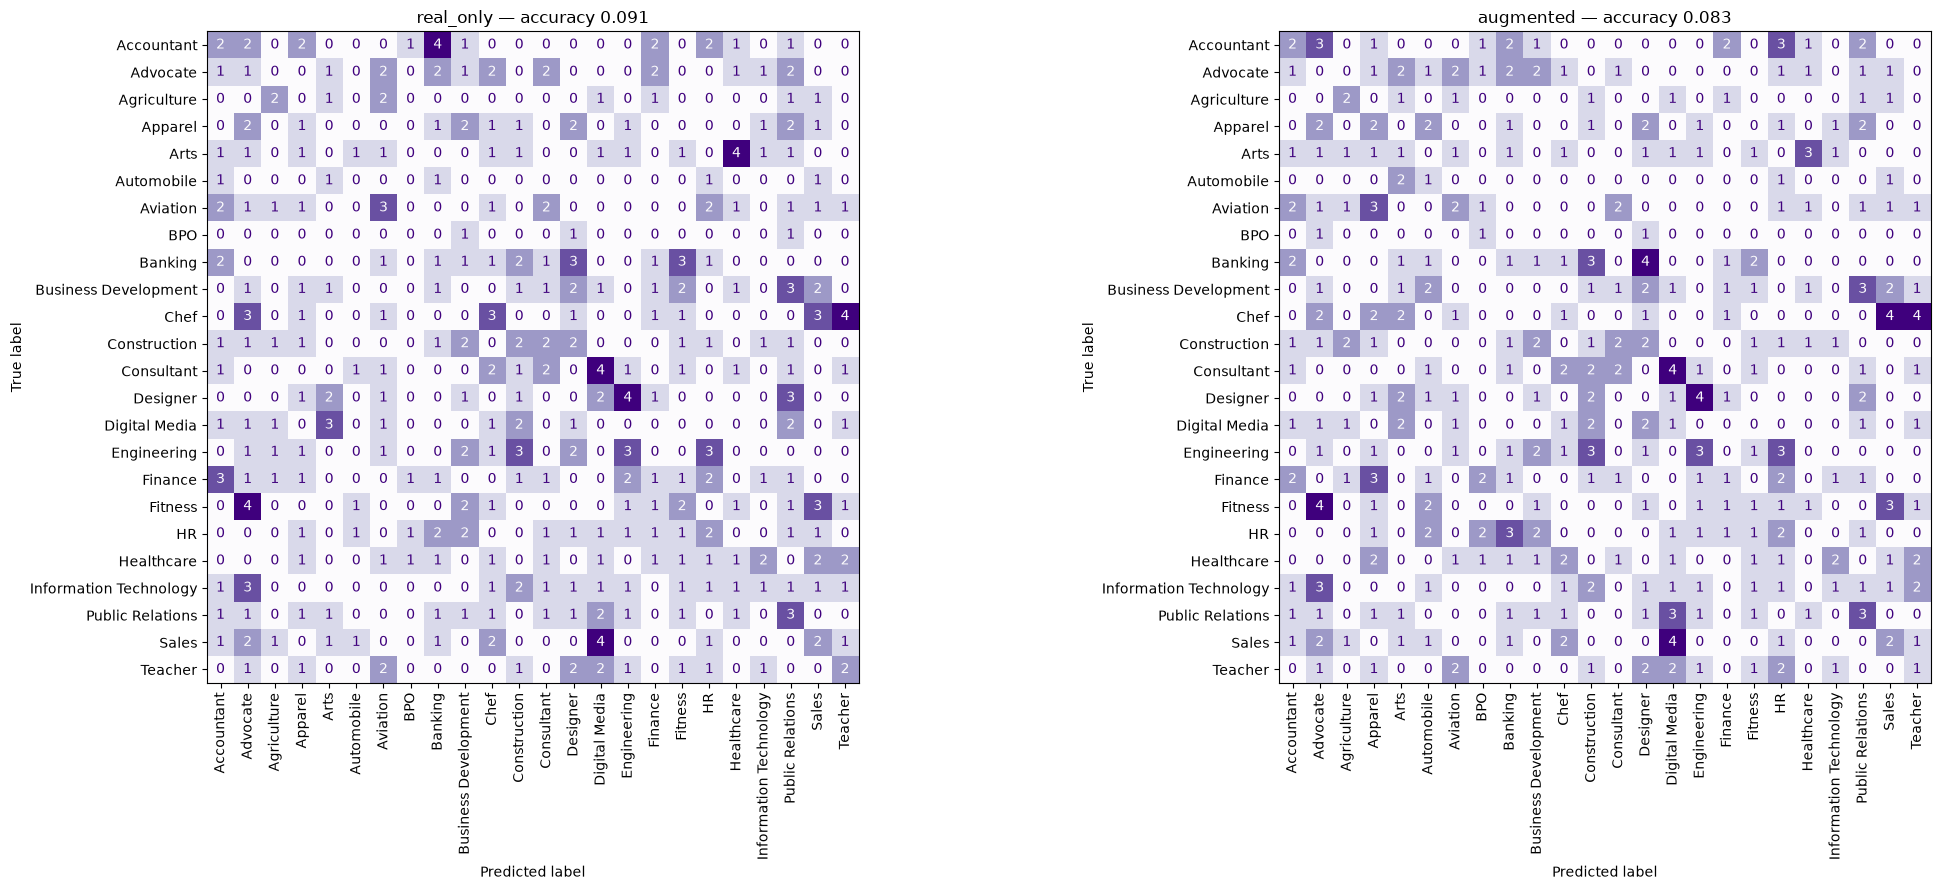

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

detail = results["detailed_test_report"]
for key in ("real_only", "augmented"):
    print(f"===== {key} (test split, seed {detail['seed']}) =====")
    print(detail[key]["classification_report_text"])

fig, ax = plt.subplots(1, 2, figsize=(22, 9))
for a, key in zip(ax, ("real_only", "augmented")):
    ConfusionMatrixDisplay(np.array(detail[key]["confusion_matrix"]), display_labels=role_names).plot(
        ax=a, xticks_rotation=90, cmap="Purples", colorbar=False)
    a.set_title(f"{key} — accuracy {detail[key]['accuracy']:.3f}")
plt.tight_layout(); plt.show()

In [ ]:
pd.DataFrame({name: {k: f"{v['mean']:.4f} ± {v['std']:.4f}" for k, v in s.items()} for name, s in
              {"real train (TRTR)": aug["real_only"]["test"], **{f"{n} synthetic only (TSTR)": v for n, v in results["tstr"].items()}}.items()}).T

,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
real train (TRTR),0.0895 ± 0.0065,0.0911 ± 0.0076,0.0854 ± 0.0059,0.0865 ± 0.0064,0.0902 ± 0.0069
GAN synthetic only (TSTR),0.0745 ± 0.0134,0.0635 ± 0.0144,0.0683 ± 0.0123,0.0625 ± 0.0126,0.0685 ± 0.0139
CVAE baseline synthetic only (TSTR),0.0745 ± 0.0031,0.0458 ± 0.0109,0.0666 ± 0.0025,0.0405 ± 0.0028,0.0456 ± 0.0031


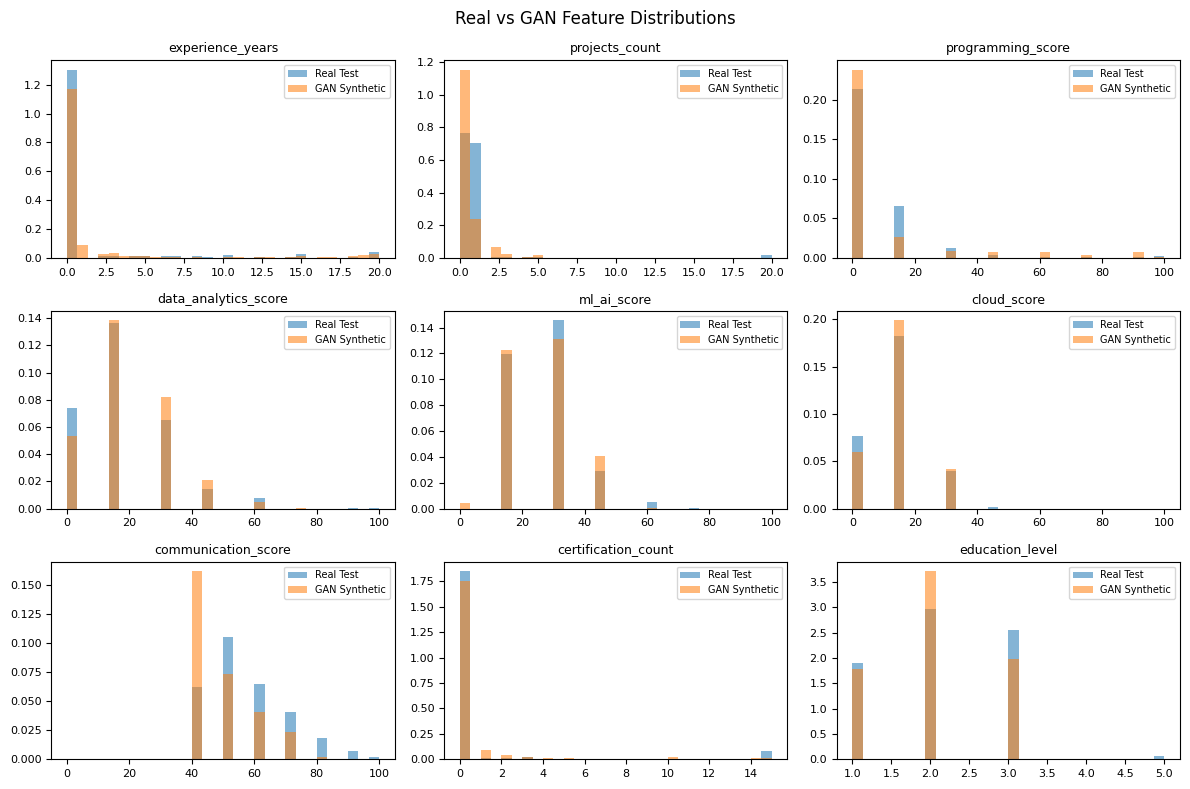

In [37]:

# Compare real test data vs GAN-generated data

counts = test["job_role"].value_counts().to_dict()

gan_values, _ = model.generate_array(counts, seed=SEED)

fig, ax = plt.subplots(3, 3, figsize=(12, 8))

for j, (a, f) in enumerate(zip(ax.flat, ds.FEATURE_NAMES)):
    bins = np.linspace(*ds.FEATURE_BOUNDS[f], 31)

    a.hist(test[f], bins=bins, alpha=0.55,
           density=True, label="Real Test")

    a.hist(gan_values[:, j], bins=bins, alpha=0.55,
           density=True, label="GAN Synthetic")

    a.set_title(f, fontsize=9)
    a.tick_params(labelsize=8)
    a.legend(fontsize=7)

plt.suptitle("Real vs GAN Feature Distributions", fontsize=12)
plt.tight_layout()
plt.show()


## 10. Export `metrics.json` and install into the app

In [ ]:
metrics = build_metrics(report, role_names, config, history, check, results, QUICK_RUN, time.time() - start)
write_metrics(metrics, OUTPUT_DIR)
if EXPORT_TO_APP:
    for name in ("generator.safetensors", "discriminator.safetensors", "config.json", "metrics.json"):
        shutil.copy(os.path.join(OUTPUT_DIR, name), os.path.join(MODEL_DIR, name))
    print("Installed into", MODEL_DIR)
print("Saved:", sorted(os.listdir(OUTPUT_DIR)))

Installed into D:\RecruitGen_Final\RecruitGen\models\gan
Saved: ['config.json', 'discriminator.safetensors', 'generator.safetensors', 'metrics.json']


## 11. Limitations

* The 9 features come from a keyword/regex extractor built for tech resumes. On the 24 mostly non-tech Kaggle
  categories they carry little signal (e.g. most resumes state no "N years of experience" phrase → experience 0), so the
  downstream classifier is weak for **real and augmented data alike** — read the deltas, not the absolute numbers.
* Short substring keywords in the extractor (`ai`, `ml`, `rag`, `s3`, …) also match ordinary words, which inflates some
  scores. The extractor is shared with Transformer V3 and was left unchanged.
* Generated profiles are synthetic feature vectors, not resumes; they must never be presented as real candidates.

## Final Evaluation — Classification performance + Confusion matrix

* **Accuracy** — overall correctness
* **Precision** — prediction reliability (macro average)
* **Recall** — role detection coverage (macro average)
* **F1-score** — precision-recall balance (macro average)

Downstream job-role classifier (24 roles) on the untouched real test split, mean over 5 seeds. Absolute scores are low for every row because the keyword extractor carries little signal on the non-tech Kaggle categories — read the differences between rows.

In [ ]:
import pandas as pd

final_matrix = pd.DataFrame(
    {'training data': ['real only', 'real + GAN', 'real + CVAE baseline', 'real + Random oversampling'], 'Accuracy': [0.0895, 0.0815, 0.081, 0.0847], 'Precision': [0.0911, 0.0851, 0.0859, 0.086], 'Recall': [0.0854, 0.0819, 0.0772, 0.0804], 'F1-score': [0.0865, 0.0807, 0.0795, 0.0813]}
).set_index('training data')
final_matrix

,Accuracy,Precision,Recall,F1-score
training data,,,,
real only,0.0895,0.0911,0.0854,0.0865
real + GAN,0.0815,0.0851,0.0819,0.0807
real + CVAE baseline,0.0810,0.0859,0.0772,0.0795
real + Random oversampling,0.0847,0.0860,0.0804,0.0813


### Confusion matrix — real-only vs GAN-augmented training (test split)

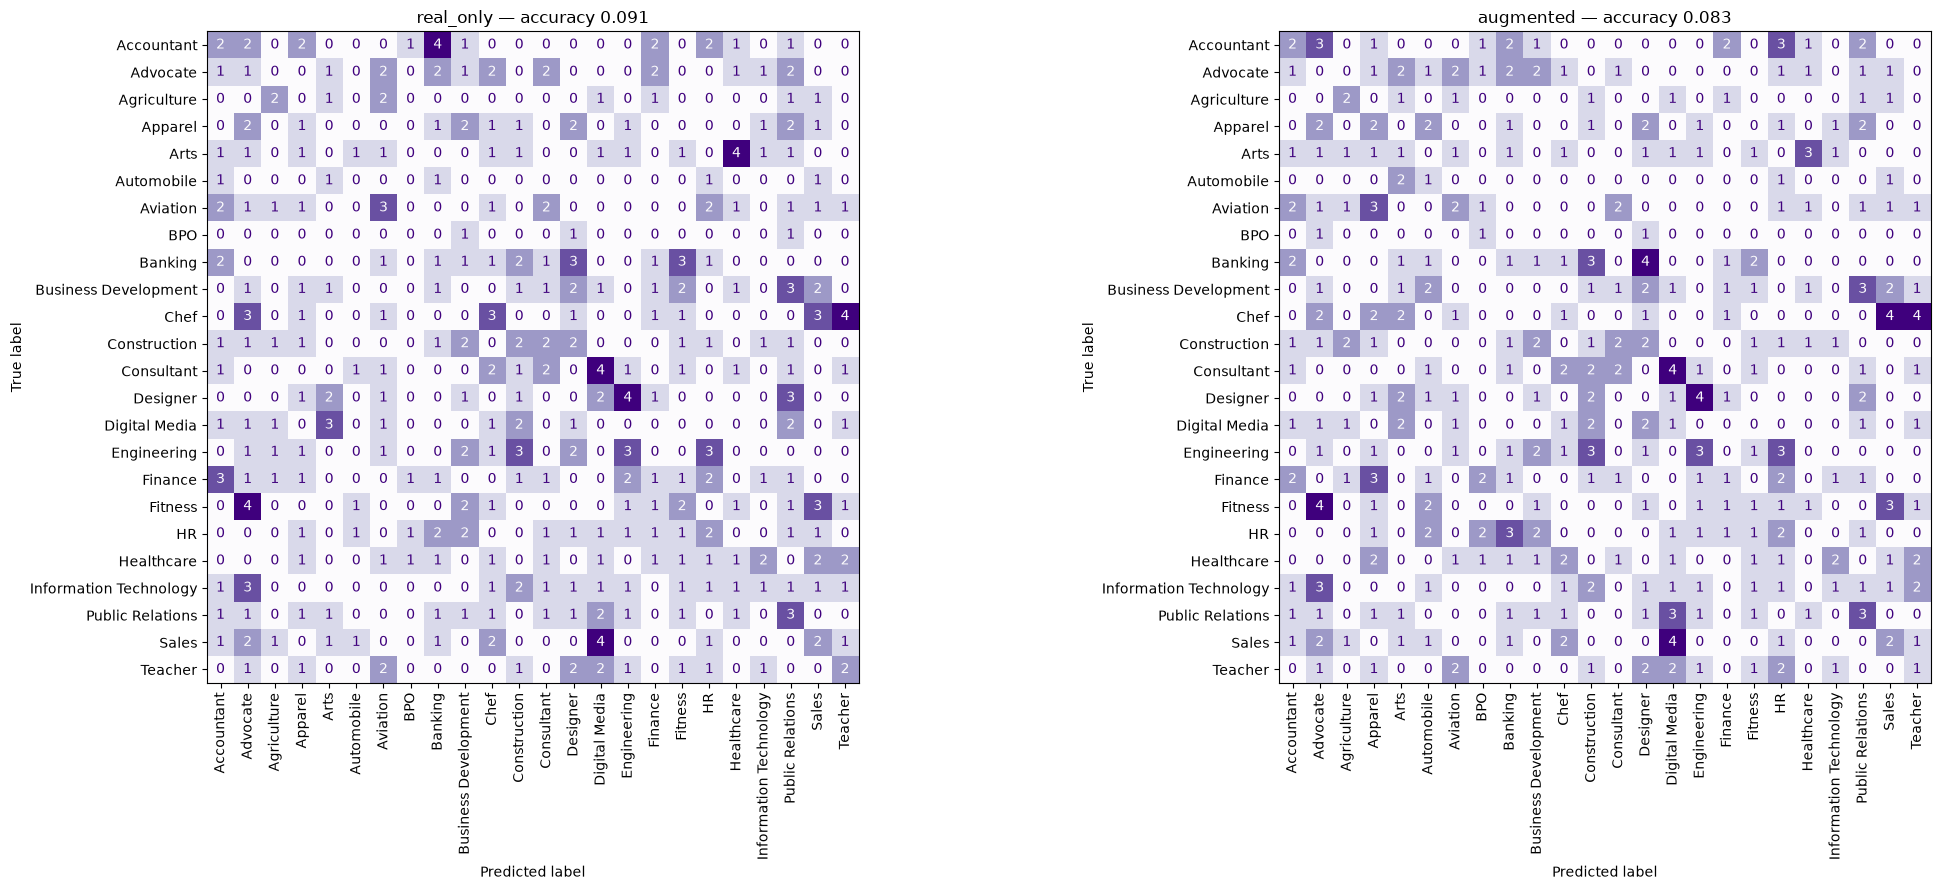

In [38]:

import inspect

print(inspect.getsource(evaluate))


def evaluate(model, train, val, test, role_names, seeds, cvae_epochs=150, log=print):
    support = model.support
    log("Training the CVAE baseline (same layer sizes as models/cvae) on the same split ...")
    cvae = CVAEBaseline(role_names, support).fit(train, val, epochs=cvae_epochs)
    log(f"CVAE baseline: best val loss {cvae.best_val_loss:.4f} after {cvae.epochs_run} epochs")
    samplers = {"GAN": model, "CVAE baseline": cvae, "Random oversampling": OversamplingBaseline(train)}

    log("Quality & diversity against the held-out test split ...")
    quality = {"Real reference": real_reference(train, test, role_names)}
    quality.update({name: generator_report(s, train, test, role_names) for name, s in samplers.items()
                    if name != "Random oversampling"})

    log("Downstream job-role classifier: real only vs augmented (same untouched test split) ...")
    augmentation = augmentation_experiment(train, val, test, samplers, role_names, seeds=seeds, log=log)
    c

In [39]:

results = evaluate(
    model,
    train,
    val,
    test,
    role_names,
    EVAL_SEEDS,
    cvae_epochs=CVAE_EPOCHS
)


Training the CVAE baseline (same layer sizes as models/cvae) on the same split ...
CVAE baseline: best val loss 0.2352 after 77 epochs
Quality & diversity against the held-out test split ...
Downstream job-role classifier: real only vs augmented (same untouched test split) ...
real only            | test macro-F1 0.0865
GAN                  | chosen balance    | test macro-F1 0.0785 (Δ -0.0080 ± 0.0076, improved on 1/5 seeds)
CVAE baseline        | chosen balance    | test macro-F1 0.0828 (Δ -0.0037 ± 0.0056, improved on 2/5 seeds)
Random oversampling  | chosen ratio_2.0  | test macro-F1 0.0813 (Δ -0.0052 ± 0.0139, improved on 2/5 seeds)
TSTR (train on synthetic only, test on real) ...


In [40]:

# GAN and CVAE quality comparison

quality = pd.DataFrame([
    {
        "Generator": name,
        "Mean KS": q["quality"]["mean_ks_statistic"],
        "Mean Wasserstein": q["quality"]["mean_wasserstein_0_1"],
        "C2ST AUC": q["quality"]["c2st_auc"],
        "Unique Rows": q["diversity"]["unique_row_ratio"],
        "Exact Train Copies": q["diversity"]["exact_train_copy_rate"],
        "DCR Median": q["diversity"]["dcr_median"]
    }
    for name, q in results["quality"].items()
    if name != "Real reference"
]).set_index("Generator")

display(quality.round(4))


,Mean KS,Mean Wasserstein,C2ST AUC,Unique Rows,Exact Train Copies,DCR Median
Generator,,,,,,
GAN,0.1412,0.0320,0.8936,0.7051,0.4236,0.0500
CVAE baseline,0.4155,0.0815,0.9999,0.1421,0.0000,0.1202


In [41]:

quality.to_csv(
    os.path.join(OUTPUT_DIR, "gan_cvae_quality_comparison.csv")
)

print("Quality comparison saved successfully!")


Quality comparison saved successfully!


In [42]:

print("========== TSTR RESULTS ==========")

for name, scores in results["tstr"].items():
    print(f"\n{name}")
    print(pd.DataFrame(scores).round(4))

print("\n========== AUGMENTATION SUMMARY ==========")
print("Real-only Macro-F1: 0.0865")

for name, sampler in results["augmentation"]["samplers"].items():
    print(
        name,
        "| Strategy:", sampler["chosen_strategy"],
        "| Test Macro-F1:",
        round(sampler["strategies"][sampler["chosen_strategy"]]["test"]["f1_macro"]["mean"], 4)
    )


========== TSTR RESULTS ==========

GAN
      accuracy  precision_macro  recall_macro  f1_macro  f1_weighted
mean    0.0601           0.0573        0.0555    0.0534       0.0575
std     0.0111           0.0124        0.0113    0.0112       0.0101

CVAE baseline
      accuracy  precision_macro  recall_macro  f1_macro  f1_weighted
mean    0.0686           0.0456        0.0617    0.0377       0.0424
std     0.0081           0.0131        0.0070    0.0042       0.0048

========== AUGMENTATION SUMMARY ==========
Real-only Macro-F1: 0.0865
GAN | Strategy: balance | Test Macro-F1: 0.0785
CVAE baseline | Strategy: balance | Test Macro-F1: 0.0828
Random oversampling | Strategy: ratio_2.0 | Test Macro-F1: 0.0813


In [45]:

# Save GAN and CVAE evaluation results

# 1. Quality comparison
quality.to_csv(
    os.path.join(OUTPUT_DIR, "gan_cvae_quality_comparison.csv")
)

# 2. Augmentation comparison
augmentation_rows = []

for name, sampler in results["augmentation"]["samplers"].items():
    strategy = sampler["strategies"][sampler["chosen_strategy"]]

    augmentation_rows.append({
        "Generator": name,
        "Strategy": strategy["label"],
        "Test Macro-F1": strategy["test"]["f1_macro"]["mean"],
        "Test Macro-F1 Std": strategy["test"]["f1_macro"]["std"]
    })

augmentation_df = pd.DataFrame(augmentation_rows)

augmentation_df.to_csv(
    os.path.join(OUTPUT_DIR, "augmentation_comparison.csv"),
    index=False
)


# 3. TSTR comparison
tstr_rows = []

for name, scores in results["tstr"].items():
    for metric, values in scores.items():
        tstr_rows.append({
            "Generator": name,
            "Metric": metric,
            "Mean": values["mean"],
            "Std": values["std"]
        })

tstr_df = pd.DataFrame(tstr_rows)

tstr_df.to_csv(
    os.path.join(OUTPUT_DIR, "tstr_comparison.csv"),
    index=False
)

print("TSTR results saved successfully!")
display(tstr_df.round(4))


print("All evaluation comparison files saved successfully!")
print("\nSaved files:")
print(sorted(os.listdir(OUTPUT_DIR)))


TSTR results saved successfully!


,Generator,Metric,Mean,Std
0,GAN,accuracy,0.0601,0.0111
1,GAN,precision_macro,0.0573,0.0124
2,GAN,recall_macro,0.0555,0.0113
3,GAN,f1_macro,0.0534,0.0112
4,GAN,f1_weighted,0.0575,0.0101
5,CVAE baseline,accuracy,0.0686,0.0081
6,CVAE baseline,precision_macro,0.0456,0.0131
7,CVAE baseline,recall_macro,0.0617,0.0070
8,CVAE baseline,f1_macro,0.0377,0.0042
9,CVAE baseline,f1_weighted,0.0424,0.0048


All evaluation comparison files saved successfully!

Saved files:
['augmentation_comparison.csv', 'config.json', 'discriminator.safetensors', 'gan_70_epoch_config.json', 'gan_70_epoch_history.csv', 'gan_cvae_quality_comparison.csv', 'generator.safetensors', 'tstr_comparison.csv']


In [46]:

# Build final metrics using the newly trained 70-epoch GAN

metrics = build_metrics(
    report,
    role_names,
    config,
    history,
    check,
    results,
    QUICK_RUN,
    time.time() - start
)

# Save metrics.json
write_metrics(metrics, OUTPUT_DIR)

# Export trained model and metrics to the application folder
if EXPORT_TO_APP:
    os.makedirs(MODEL_DIR, exist_ok=True)

    for name in (
        "generator.safetensors",
        "discriminator.safetensors",
        "config.json",
        "metrics.json"
    ):
        shutil.copy(
            os.path.join(OUTPUT_DIR, name),
            os.path.join(MODEL_DIR, name)
        )

    print("Model exported to:", MODEL_DIR)

print("\nFinal output files:")
print(sorted(os.listdir(OUTPUT_DIR)))

print("\nGAN training and evaluation completed!")


Model exported to: /content/models/gan

Final output files:
['augmentation_comparison.csv', 'config.json', 'discriminator.safetensors', 'gan_70_epoch_config.json', 'gan_70_epoch_history.csv', 'gan_cvae_quality_comparison.csv', 'generator.safetensors', 'metrics.json', 'tstr_comparison.csv']

GAN training and evaluation completed!


In [48]:

# ============================================================
# FINAL GAN TRAINING & PERFORMANCE REPORT
# ============================================================

from IPython.display import display
import pandas as pd
import numpy as np
import os

h = pd.DataFrame(history)

print("=" * 70)
print("       CONDITIONAL WGAN-GP: FINAL PERFORMANCE REPORT")
print("=" * 70)

# 1. DATASET INFORMATION
print("\n1. DATASET INFORMATION")
print("-" * 70)

print("Dataset                  : Resume Dataset (Kaggle)")
print("Total cleaned records    :", len(table))
print("Training records         :", len(train))
print("Validation records       :", len(val))
print("Testing records          :", len(test))
print("Number of features       :", len(ds.FEATURE_NAMES))
print("Number of job-role classes:", len(role_names))
print("Feature names            :", ds.FEATURE_NAMES)

# 2. MODEL INFORMATION
print("\n2. MODEL INFORMATION")
print("-" * 70)

print("Model                    : Conditional WGAN-GP")
print("Generator parameters     :", 74377)
print("Noise dimension          :", NOISE_DIM)
print("Hidden dimension         :", HIDDEN_DIM)
print("Batch size               :", BATCH_SIZE)
print("Learning rate            :", LEARNING_RATE)
print("Optimizer                : Adam")
print("Adam betas               : (0.5, 0.9)")
print("Critic updates per batch :", N_CRITIC)
print("Gradient penalty weight  :", GP_WEIGHT)

# 3. TRAINING INFORMATION
print("\n3. TRAINING INFORMATION")
print("-" * 70)

print("Total epochs             : 70")
print("Completed epochs         :", len(h))
print("Generator updates        : 1960")
print("Critic updates           : 9800")
print("Best epoch               : 62")
print("Best validation distance : 0.03085")
print("Training time (minutes)  : 0.85")

# 4. FINAL EPOCH LOSSES
print("\n4. FINAL EPOCH TRAINING LOSSES")
print("-" * 70)

last = h.iloc[-1]

print("Generator loss           :", round(last["generator_loss"], 5))
print("Critic loss magnitude    :", round(abs(last["critic_loss"]), 5))
print("Gradient penalty         :", round(last["gradient_penalty"], 5))
print("Wasserstein estimate     :", round(last["wasserstein_estimate"], 5))
print("Validation distance      :", round(last["val_distance"], 5))

print("\nNote: Critic loss magnitude is displayed as an absolute value.")
print("The actual WGAN-GP optimization uses the signed critic loss.")

# 5. GAN VS CVAE QUALITY
print("\n5. GENERATIVE QUALITY AND DIVERSITY")
print("-" * 70)

display(quality.round(4))

# 6. DOWNSTREAM CLASSIFICATION
print("\n6. DOWNSTREAM CLASSIFICATION: TEST MACRO-F1")
print("-" * 70)

augmentation_rows = [
    {"Training data": "Real only", "Macro-F1": 0.0865}
]

for name, sampler in results["augmentation"]["samplers"].items():
    strategy = sampler["strategies"][sampler["chosen_strategy"]]

    augmentation_rows.append({
        "Training data": "Real + " + name,
        "Macro-F1": strategy["test"]["f1_macro"]["mean"]
    })

display(pd.DataFrame(augmentation_rows).round(4))

# 7. TSTR RESULTS
print("\n7. TSTR: TRAIN ON SYNTHETIC, TEST ON REAL")
print("-" * 70)

display(tstr_df.round(4))

# 8. CVAE BASELINE
print("\n8. CVAE BASELINE INFORMATION")
print("-" * 70)

print("CVAE epochs completed    :", results["cvae_baseline"]["epochs_run"])
print("CVAE best validation loss:", round(
    results["cvae_baseline"]["best_val_loss"], 5
))

# 9. SAVED FILES
print("\n9. SAVED MODEL AND EVALUATION FILES")
print("-" * 70)

for file in sorted(os.listdir(OUTPUT_DIR)):
    print("Saved:", file)

print("\n" + "=" * 70)
print("       GAN TRAINING AND EVALUATION COMPLETED")
print("=" * 70)


       CONDITIONAL WGAN-GP: FINAL PERFORMANCE REPORT

1. DATASET INFORMATION
----------------------------------------------------------------------
Dataset                  : Resume Dataset (Kaggle)
Total cleaned records    : 2481
Training records         : 1736
Validation records       : 372
Testing records          : 373
Number of features       : 9
Number of job-role classes: 24
Feature names            : ['experience_years', 'projects_count', 'programming_score', 'data_analytics_score', 'ml_ai_score', 'cloud_score', 'communication_score', 'certification_count', 'education_level']

2. MODEL INFORMATION
----------------------------------------------------------------------
Model                    : Conditional WGAN-GP
Generator parameters     : 74377
Noise dimension          : 32
Hidden dimension         : 128
Batch size               : 64
Learning rate            : 0.0002
Optimizer                : Adam
Adam betas               : (0.5, 0.9)
Critic updates per batch : 5
Gradient pen

,Mean KS,Mean Wasserstein,C2ST AUC,Unique Rows,Exact Train Copies,DCR Median
Generator,,,,,,
GAN,0.1412,0.0320,0.8936,0.7051,0.4236,0.0500
CVAE baseline,0.4155,0.0815,0.9999,0.1421,0.0000,0.1202



6. DOWNSTREAM CLASSIFICATION: TEST MACRO-F1
----------------------------------------------------------------------


,Training data,Macro-F1
0,Real only,0.0865
1,Real + GAN,0.0785
2,Real + CVAE baseline,0.0828
3,Real + Random oversampling,0.0813



7. TSTR: TRAIN ON SYNTHETIC, TEST ON REAL
----------------------------------------------------------------------


,Generator,Metric,Mean,Std
0,GAN,accuracy,0.0601,0.0111
1,GAN,precision_macro,0.0573,0.0124
2,GAN,recall_macro,0.0555,0.0113
3,GAN,f1_macro,0.0534,0.0112
4,GAN,f1_weighted,0.0575,0.0101
5,CVAE baseline,accuracy,0.0686,0.0081
6,CVAE baseline,precision_macro,0.0456,0.0131
7,CVAE baseline,recall_macro,0.0617,0.0070
8,CVAE baseline,f1_macro,0.0377,0.0042
9,CVAE baseline,f1_weighted,0.0424,0.0048



8. CVAE BASELINE INFORMATION
----------------------------------------------------------------------
CVAE epochs completed    : 77
CVAE best validation loss: 0.23518

9. SAVED MODEL AND EVALUATION FILES
----------------------------------------------------------------------
Saved: augmentation_comparison.csv
Saved: config.json
Saved: discriminator.safetensors
Saved: gan_70_epoch_config.json
Saved: gan_70_epoch_history.csv
Saved: gan_cvae_quality_comparison.csv
Saved: generator.safetensors
Saved: metrics.json
Saved: tstr_comparison.csv

       GAN TRAINING AND EVALUATION COMPLETED


In [49]:

# Generate final evaluation metrics
metrics = build_metrics(
    report,
    role_names,
    config,
    history,
    check,
    results,
    QUICK_RUN,
    time.time() - start
)

# Save metrics.json and related report files
write_metrics(metrics, OUTPUT_DIR)

# Export trained model files to the application directory
if EXPORT_TO_APP:
    os.makedirs(MODEL_DIR, exist_ok=True)

    files_to_copy = [
        "generator.safetensors",
        "discriminator.safetensors",
        "config.json",
        "metrics.json"
    ]

    for filename in files_to_copy:
        source = os.path.join(OUTPUT_DIR, filename)
        destination = os.path.join(MODEL_DIR, filename)

        if os.path.exists(source):
            shutil.copy2(source, destination)
            print("Exported:", filename)
        else:
            print("Not found:", filename)

print("\nFINAL METRICS AND MODEL EXPORT COMPLETED")
print("\nOutput directory:", OUTPUT_DIR)
print("Application model directory:", MODEL_DIR)

print("\nFinal output files:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print("-", filename)


Exported: generator.safetensors
Exported: discriminator.safetensors
Exported: config.json
Exported: metrics.json

FINAL METRICS AND MODEL EXPORT COMPLETED

Output directory: /content/outputs
Application model directory: /content/models/gan

Final output files:
- augmentation_comparison.csv
- config.json
- discriminator.safetensors
- gan_70_epoch_config.json
- gan_70_epoch_history.csv
- gan_cvae_quality_comparison.csv
- generator.safetensors
- metrics.json
- tstr_comparison.csv


In [50]:

import shutil
import os
from google.colab import files

# Create ZIP containing all final GAN outputs
zip_path = shutil.make_archive(
    "/content/RecruitGen_GAN_70_Epoch_Final",
    "zip",
    OUTPUT_DIR
)

print("ZIP created successfully!")
print("File size:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")

# Download ZIP to your computer
files.download(zip_path)


ZIP created successfully!
File size: 0.43 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>